# Label-Free Particle Classification from SEALS Spectra

**Label-free** means the particle is identified from how it **scatters light**, with no
fluorescent tag. The classifier is still trained on examples of known class. The SEALS paper
(Adam … Jalali, *Opt. Express* 2013) argues that a whole **angular spectrum** carries far more
morphological information than the two numbers a conventional flow cytometer records (forward
and side scatter). This notebook tests that claim on synthetic data:

| § | content | tools |
|---|---|---|
| 1 | synthetic SEALS spectra for three bead sizes | `scarlett.physics` Mie + SEALS map |
| 2 | Gini impurity, derived (Lagrange multipliers) | **SymPy** |
| 3 | 2 angles vs. the full spectrum | **from-scratch** random forest (`dgs.decision_tree`) + scikit-learn |
| 4 | what the tree actually learns: splits and important angles | decision tree, feature importance |
| 5 | the same data in **MATLAB**, run from this notebook | `fitctree` (Gini) + `TreeBagger` |

**Synthetic only:** Mie theory, the published SEALS map, and a stated noise model. No measured data.

In [1]:
import sys, pathlib, subprocess, shutil, tempfile
ROOT = pathlib.Path.cwd().parent
sys.path.insert(0, str(ROOT / "src")); sys.path.insert(0, str(ROOT.parent))     # scarlett + repo (dgs)
import numpy as np
import sympy as sp
import matplotlib.pyplot as plt
from IPython.display import display, Math
sp.init_printing()
from scarlett import label_free as lf
from dgs.decision_tree import RandomForest, DecisionTree, accuracy
from sklearn.ensemble import RandomForestClassifier
from sklearn.tree import DecisionTreeClassifier, export_text
from sklearn.metrics import confusion_matrix

# 1. Synthetic SEALS spectra

Three polystyrene-bead classes (7.32, 8.5, 9.94 µm; $n = 1.39$ as in the paper). Each particle
gets a 2% size spread, a ±0.01 index spread, 5% per-angle noise, and a random overall brightness
factor (±30%: laser power, position in the focus). Its spectrum is read through the SEALS map
at 42 resolvable angles, the paper's number, with the detector 20° off axis.

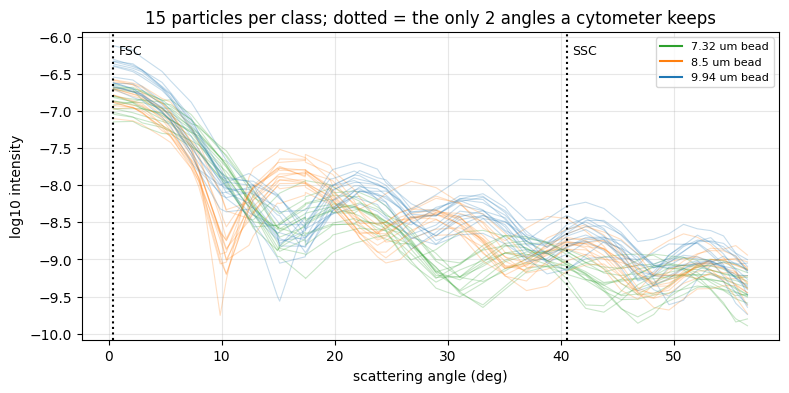

450 particles × 42 angles;  conventional features at 0.4° and 40.5°


In [2]:
X, y, ang, names = lf.make_dataset(gain_jitter=0.3, seed=0)
deg = np.degrees(ang); order = np.argsort(deg)
fig, ax = plt.subplots(figsize=(9, 4))
for c, col in zip(range(3), ("C2", "C1", "C0")):
    for row in X[y == c][:15]:
        ax.plot(deg[order], row[order], color=col, alpha=0.25, lw=0.8)
    ax.plot([], [], color=col, label=names[c])
F2, (f_deg, s_deg) = lf.conventional_features(X, ang)
for a_ in (f_deg, s_deg):
    ax.axvline(a_, color="k", ls=":")
ax.text(f_deg + 0.5, ax.get_ylim()[1] - 0.3, "FSC", fontsize=9); ax.text(s_deg + 0.5, ax.get_ylim()[1] - 0.3, "SSC", fontsize=9)
ax.set(xlabel="scattering angle (deg)", ylabel="log10 intensity", title="15 particles per class; dotted = the only 2 angles a cytometer keeps")
ax.legend(fontsize=8); ax.grid(alpha=0.3); plt.show()
print(f"{X.shape[0]} particles × {X.shape[1]} angles;  conventional features at {f_deg:.1f}° and {s_deg:.1f}°")

# 2. Gini impurity, derived

A tree splits data to make each side as **pure** as possible. Gini impurity measures how mixed a
node is: the chance that two random picks from the node are *different* classes,
$G = 1 - \sum_k p_k^2$. Where is it worst? Maximize with the constraint $\sum p_k = 1$ (Lagrange
multipliers):

<IPython.core.display.Math object>

<IPython.core.display.Math object>

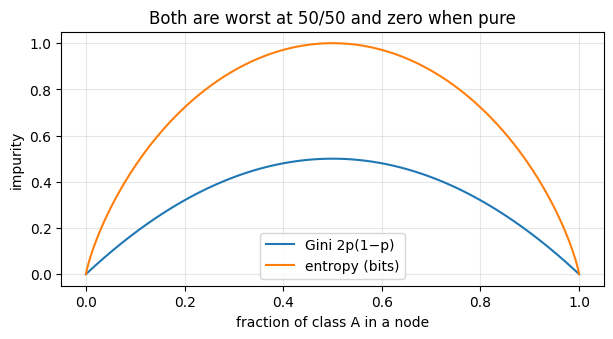

In [3]:
G, sol, Gmax = lf.gini_symbolic(3)
display(Math(r"G = " + sp.latex(G) + r",\quad \nabla(G - \mu(\textstyle\sum p - 1)) = 0 \Rightarrow " + sp.latex(sol) + r",\quad G_\max = " + sp.latex(Gmax)))
g2, H, p = lf.gini_binary_vs_entropy()
display(Math(r"\text{two classes: } G(p) = " + sp.latex(g2) + r",\qquad H(p) = " + sp.latex(H)))
pp = np.linspace(1e-6, 1 - 1e-6, 400)
fig, ax = plt.subplots(figsize=(7, 3.3))
ax.plot(pp, 2*pp*(1-pp), label="Gini 2p(1−p)"); ax.plot(pp, -(pp*np.log2(pp) + (1-pp)*np.log2(1-pp)), label="entropy (bits)")
ax.set(xlabel="fraction of class A in a node", ylabel="impurity", title="Both are worst at 50/50 and zero when pure"); ax.legend(); ax.grid(alpha=0.3); plt.show()

# 3. Two angles vs. the whole spectrum

Same particles, same train/test split (60/40). Two random forests are compared:
`dgs.decision_tree.RandomForest`, written from scratch in this repo with the Gini criterion,
and scikit-learn's as an independent check. Both feature sets are tested **with and without**
the brightness jitter. Absolute intensity is all two angles can offer, so the jitter is the
fair stress test.

In [4]:
rows = []
for gj in (0.0, 0.3):
    Xg, yg, angg, _ = lf.make_dataset(gain_jitter=gj, seed=0)
    tr, te = lf.split(len(yg))
    F2g, _ = lf.conventional_features(Xg, angg)
    for name, F in (("2 angles (FSC+SSC)", F2g), ("SEALS 42 angles", Xg)):
        ours = RandomForest(n_estimators=60, max_depth=8, criterion="gini", random_state=0).fit(F[tr], yg[tr])
        sk = RandomForestClassifier(200, random_state=0).fit(F[tr], yg[tr])
        rows.append((gj, name, accuracy(yg[te], ours.predict(F[te])), sk.score(F[te], yg[te])))
print(f"{'brightness jitter':>18s} {'features':20s} {'from-scratch RF':>16s} {'scikit-learn RF':>16s}")
for gj, name, a1, a2 in rows:
    print(f"{gj:18.1f} {name:20s} {a1:16.3f} {a2:16.3f}")

 brightness jitter features              from-scratch RF  scikit-learn RF
               0.0 2 angles (FSC+SSC)              0.889            0.872
               0.0 SEALS 42 angles                 1.000            1.000
               0.3 2 angles (FSC+SSC)              0.689            0.672
               0.3 SEALS 42 angles                 1.000            1.000


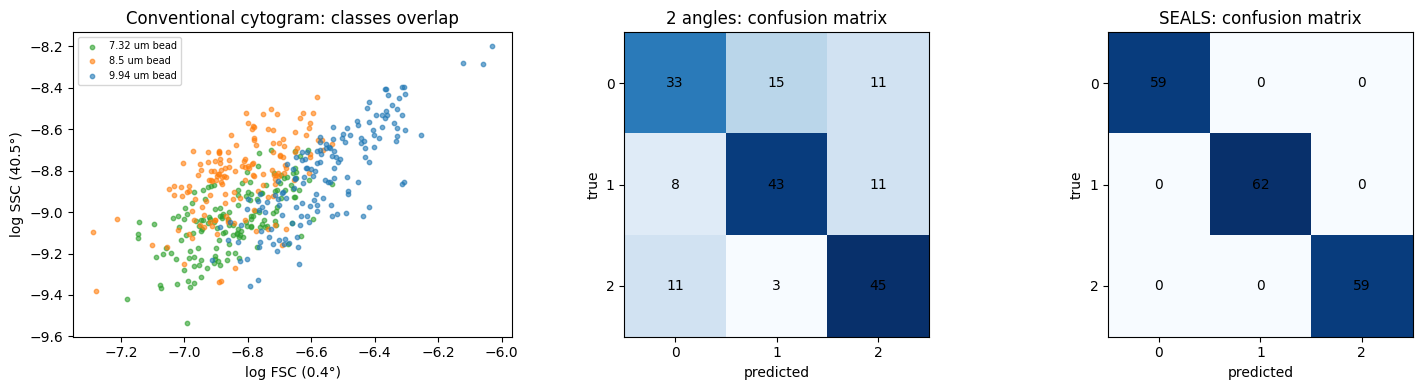

In [5]:
X, y, ang, names = lf.make_dataset(gain_jitter=0.3, seed=0); tr, te = lf.split(len(y)); F2, _ = lf.conventional_features(X, ang)
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for c, col in zip(range(3), ("C2", "C1", "C0")):
    axes[0].scatter(F2[y == c, 0], F2[y == c, 1], s=10, color=col, alpha=0.6, label=names[c])
axes[0].set(xlabel=f"log FSC ({f_deg:.1f}°)", ylabel=f"log SSC ({s_deg:.1f}°)", title="Conventional cytogram: classes overlap"); axes[0].legend(fontsize=7)
for ax, (name, F) in zip(axes[1:], (("2 angles", F2), ("SEALS", X))):
    cm = confusion_matrix(y[te], RandomForestClassifier(200, random_state=0).fit(F[tr], y[tr]).predict(F[te]))
    ax.imshow(cm, cmap="Blues"); ax.set(title=f"{name}: confusion matrix", xlabel="predicted", ylabel="true", xticks=range(3), yticks=range(3))
    for i in range(3):
        for j in range(3):
            ax.text(j, i, cm[i, j], ha="center", va="center")
plt.tight_layout(); plt.show()

# 4. What does the tree learn?

A shallow (depth-3) Gini tree is small enough to read. Each split asks *"is the log intensity at
angle θ above t?"*. The forest's feature importances show **which angles carry the information**.
In SEALS terms, that says which wavelengths of the rainbow matter.

|--- I(31.1°) <= -8.91
|   |--- I(10.4°) <= -8.25
|   |   |--- I(10.4°) <= -8.86
|   |   |   |--- class: 8.5 um bead
|   |   |--- I(10.4°) >  -8.86
|   |   |   |--- class: 9.94 um bead
|   |--- I(10.4°) >  -8.25
|   |   |--- class: 7.32 um bead
|--- I(31.1°) >  -8.91
|   |--- I(17.4°) <= -8.17
|   |   |--- I(10.4°) <= -9.12
|   |   |   |--- class: 8.5 um bead
|   |   |--- I(10.4°) >  -9.12
|   |   |   |--- class: 9.94 um bead
|   |--- I(17.4°) >  -8.17
|   |   |--- I(10.4°) <= -8.10
|   |   |   |--- class: 8.5 um bead
|   |   |--- I(10.4°) >  -8.10
|   |   |   |--- class: 7.32 um bead

depth-3 tree test accuracy: 0.978


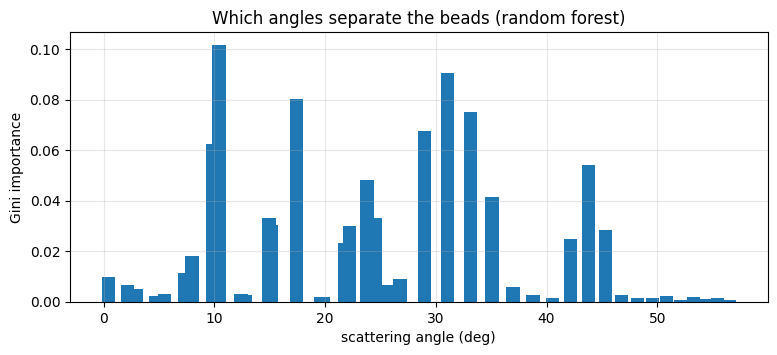

In [6]:
fnames = [f"I({d:.1f}°)" for d in np.degrees(ang)]
small = DecisionTreeClassifier(max_depth=3, criterion="gini", random_state=0).fit(X[tr], y[tr])
print(export_text(small, feature_names=fnames, class_names=names))
print(f"depth-3 tree test accuracy: {small.score(X[te], y[te]):.3f}")
imp = RandomForestClassifier(300, random_state=0).fit(X[tr], y[tr]).feature_importances_
o = np.argsort(np.degrees(ang))
fig, ax = plt.subplots(figsize=(9, 3.5))
ax.bar(np.degrees(ang)[o], imp[o], width=1.2)
ax.set(xlabel="scattering angle (deg)", ylabel="Gini importance", title="Which angles separate the beads (random forest)"); ax.grid(alpha=0.3); plt.show()

# 5. MATLAB from this notebook

The same train/test data, exported to CSV, then fed to MATLAB's `fitctree` (`'SplitCriterion','gdi'`,
where gdi is Gini's diversity index) and a 60-tree `TreeBagger`. The script is
[`matlab/label_free_fitctree.m`](../matlab/label_free_fitctree.m). The cell runs MATLAB headless
if it's installed and skips otherwise.

In [7]:
matlab = shutil.which("matlab") or r"C:\Program Files\MATLAB\R2025b\bin\matlab.exe"
tmp = pathlib.Path(tempfile.mkdtemp())
lf.export_csv(tmp / "train.csv", X[tr], y[tr]); lf.export_csv(tmp / "test.csv", X[te], y[te])
if pathlib.Path(matlab).exists():
    cmd = f"addpath('matlab'); label_free_fitctree('{(tmp/'train.csv').as_posix()}','{(tmp/'test.csv').as_posix()}')"
    out = subprocess.run([matlab, "-batch", cmd], cwd=ROOT, capture_output=True, text=True, timeout=900).stdout
    print("\n".join(l for l in out.splitlines() if "accuracy" in l))
else:
    print("MATLAB not found — skipped")
print(f"Python, same split:  sklearn tree {DecisionTreeClassifier(max_depth=None, criterion='gini', random_state=0).fit(X[tr], y[tr]).score(X[te], y[te]):.4f},"
      f"  sklearn forest {RandomForestClassifier(200, random_state=0).fit(X[tr], y[tr]).score(X[te], y[te]):.4f}")

MATLAB fitctree (gini)   test accuracy = 0.9778
MATLAB TreeBagger (60)   test accuracy = 1.0000
Python, same split:  sklearn tree 0.9833,  sklearn forest 1.0000


# Summary

| features | 2 angles (cytometer) | 42 angles (SEALS) |
|---|---|---|
| no brightness jitter | ~0.87 | 1.00 |
| ±30% brightness jitter | ~0.67 | 1.00 |

On this synthetic problem the full angular spectrum separates bead sizes that two fixed angles
confuse, which is the paper's argument made quantitative. Real cells are harder: non-spherical,
inhomogeneous, and lacking a Mie ground truth. That's where Jalali's lab moved from trees to
deep learning on time-stretch data.

## Exercises
1. Shrink `size_cv` toward 0 and raise it to 5%. At what spread does SEALS start to fail?
2. Use only every 4th SEALS angle (≈10 angles). How much accuracy is lost?
3. Replace `criterion="gini"` with `"entropy"` in the from-scratch forest. Any difference?
4. Add a fourth class with the same size but $n = 1.45$. Can either feature set tell refractive index apart from size?